# Exploratory Data Analysis (EDA)

Explore the cleaned retail sales data to understand distributions, patterns, trends, and business insights before statistical analysis.

هنا الان في البداية نحمل النسخ النظيفة اللي سويناها في الخطوة اللي قبل

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

regions = pd.read_csv("../../data/processed/Regions_clean.csv")
products = pd.read_csv("../../data/processed/Products_clean.csv")
customers = pd.read_csv("../../data/processed/Customers_clean.csv")
orders = pd.read_csv("../../data/processed/Orders_clean.csv")
order_items = pd.read_csv("../../data/processed/OrderItems_clean.csv")

بعدها هنا نعدل التواريخ لان بالغالب ترجع لنا object وقت القراءة عشان كذا نحولها علطول

In [2]:
customers["RegistrationDate"] = pd.to_datetime(customers["RegistrationDate"])
orders["OrderDate"] = pd.to_datetime(orders["OrderDate"])

وهنا بس نتاكد من الاحجام 

In [3]:
print("Regions:", regions.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)

Regions: (5, 2)
Products: (100, 7)
Customers: (995, 10)
Orders: (5000, 6)
Order Items: (13346, 6)


## 1. Order Status Distribution

Explore the distribution of order statuses before calculating sales metrics.

طبعا لازم قبل كل شي نفهم حالة الطلبات لان بعها موكد وملغي وطلب جديد ما ينفع نعاملها كانها طلبات محققة لا ... لذا نشوف العدد من خلال هذا 
هنا بيعطينا كم طلب في كل حالة 

In [4]:
orders["OrderStatus"].value_counts()

OrderStatus
Completed    4038
Cancelled     363
Returned      323
Pending       276
Name: count, dtype: int64

والامر هذا نفس السابق بس يقول لنا نسبة كل حالة من اجمالي الطلبات ... والنسبة دايم تكون اوضح من العدد فقط 

In [5]:
orders["OrderStatus"].value_counts(normalize=True).mul(100).round(2)

OrderStatus
Completed    80.76
Cancelled     7.26
Returned      6.46
Pending       5.52
Name: proportion, dtype: float64

## 2. Completed Sales Dataset

Create a sales dataset using completed orders only, then combine order details with product information for revenue analysis.

In [6]:
completed_orders = orders[
    orders["OrderStatus"] == "Completed"
].copy()

completed_orders.shape

(4038, 6)

In [7]:
sales = order_items.merge(
    completed_orders,
    on="OrderID",
    how="inner"
)

sales.shape

(10812, 11)

In [8]:
sales["SalesAmount"] = (
    sales["Quantity"]
    * sales["UnitPrice"]
    * (1 - sales["DiscountPercent"] / 100)
)

In [9]:
sales.head()

,OrderItemID,OrderID,ProductID,Quantity,UnitPrice,DiscountPercent,CustomerID,OrderDate,OrderStatus,PaymentMethod,ShippingMethod,SalesAmount
0,6,2,62,3,516.52,15,424,2025-06-02,Completed,Card,Delivery,1317.1260
1,7,2,76,1,590.41,20,424,2025-06-02,Completed,Card,Delivery,472.3280
2,8,3,68,1,2338.01,5,660,2024-02-28,Completed,Cash,Delivery,2221.1095
3,9,3,19,2,3416.16,10,660,2024-02-28,Completed,Cash,Delivery,6149.0880
4,10,4,14,2,3098.08,15,575,2024-01-09,Completed,Card,Delivery,5266.7360


الفكرة ببساطة لما سبق للاوامر اللي فوق اضفت قيمة المبيعات لكل  سطر مع الخصم عشان اشوف الايرادات المحققة صح 
ابسطها اكثر 
SalesAmount = Quantity × UnitPrice × (1 - Discount%)
يعني مثال سريع 
منتج سعره 100، الكمية 2، الخصم 10%
2 × 100 × 0.90 = 180

 طبعا بعد هذا كله الحين جاء الوقت اللي نطلع أول KPI  من الـ Total Revenue
 والناتج بيكون طبعا 
إجمالي المبيعات من الطلبات المكتملة فقط بعد ما حسبنا الخصم

In [10]:
total_revenue = sales["SalesAmount"].sum()

total_revenue

np.float64(25746272.0155)

In [11]:
print(f"Total Revenue: {total_revenue:,.2f}")

Total Revenue: 25,746,272.02


بعدها علطول نحسب Average Order Value
كن مهم هنا ما نأخذ متوسط SalesAmount على مستوى الـOrder Item
لأن هذا بيعطينا متوسط السطر وليس متوسط الطلب
عشان كذا اول شي نسويه نجمع المبيعات لكل طلب

In [12]:
order_sales = (
    sales.groupby("OrderID")["SalesAmount"]
    .sum()
    .reset_index()
)

In [13]:
average_order_value = order_sales["SalesAmount"].mean()

print(f"Average Order Value: {average_order_value:,.2f}")

Average Order Value: 6,376.00


والنتاج الحين مع اللي قبل ممتاز ومنطقي معه يعني والـAOV منطقي مرررة 
والحين نكمل KPI ثالث بسيط ومهم
Total Quantity Sold

In [15]:
total_quantity_sold = sales["Quantity"].sum()

print(f"Total Quantity Sold: {total_quantity_sold:,}")

Total Quantity Sold: 20,367


بعدها نشوف أول Trend حقيقي في الـ
EDA المبيعات حسب الشهر
واللي من خلاله بعدين نقدر نسوي شارت لاين عليه 
يعني اشوف الصدق ان المتعة بالتحليل بدت الحين 

In [16]:
sales["YearMonth"] = sales["OrderDate"].dt.to_period("M")

In [17]:
monthly_sales = (
    sales.groupby("YearMonth")["SalesAmount"]
    .sum()
    .reset_index()
)

monthly_sales

,YearMonth,SalesAmount
0,2024-01,1.225435e+06
1,2024-02,1.056767e+06
2,2024-03,1.035762e+06
3,2024-04,1.123893e+06
4,2024-05,1.124009e+06
5,2024-06,1.038212e+06
6,2024-07,9.863305e+05
7,2024-08,1.145439e+06
8,2024-09,1.130914e+06
9,2024-10,1.023502e+06


والحين  نقدر نسوي أول Visualization فعلي في EDA Monthly Sales Trend.

قبل الرسم، ضروري نحول YearMonth من Period إلى نص عشان المحور يطلع لنا بشكل حلو  

In [18]:
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

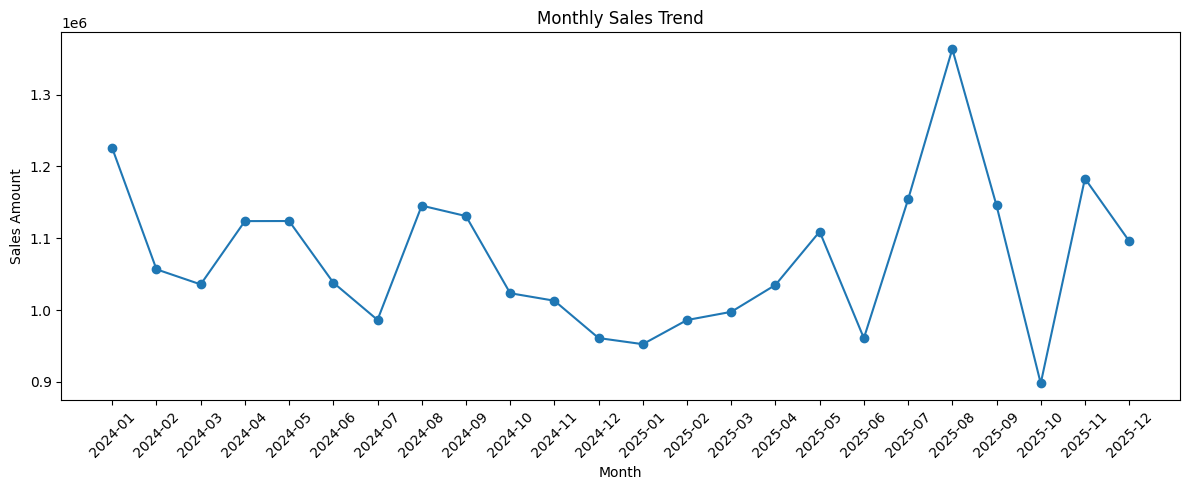

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["SalesAmount"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

بعدها علول نخليها 
Yearly Sales Comparison: 2024 vs 2025 
عشان نعرف هل السنة الثانية فسها تحسن أو لا

## 3. Yearly Sales Comparison

Compare total completed sales between 2024 and 2025.

In [20]:
sales["Year"] = sales["OrderDate"].dt.year

yearly_sales = (
    sales.groupby("Year")["SalesAmount"]
    .sum()
    .reset_index()
)

yearly_sales

,Year,SalesAmount
0,2024,1.286436e+07
1,2025,1.288191e+07


In [21]:
sales_2024 = yearly_sales.loc[
    yearly_sales["Year"] == 2024,
    "SalesAmount"
].iloc[0]

sales_2025 = yearly_sales.loc[
    yearly_sales["Year"] == 2025,
    "SalesAmount"
].iloc[0]

growth_rate = ((sales_2025 - sales_2024) / sales_2024) * 100

print(f"2024 Sales: {sales_2024:,.2f}")
print(f"2025 Sales: {sales_2025:,.2f}")
print(f"Growth Rate: {growth_rate:.2f}%")

2024 Sales: 12,864,362.41
2025 Sales: 12,881,909.61
Growth Rate: 0.14%


النتيجة تقول لنا ان المبيعات السنوية شبه مستقرة تقريبا 
يعني ما عندنا نمو سنوي جوهري، على انه فيه اختلافات واضحة بين الأشهر
وطبعا هذا بحد ذاته استنتاج والملاحظة ممتاززة ...  التذبذب الشهري موجود بس القيمة السنوية مستقرة تقريبًا

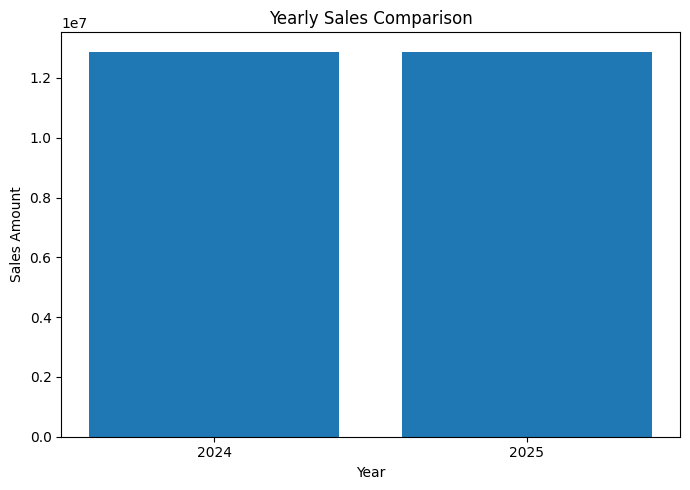

In [22]:
plt.figure(figsize=(7, 5))

plt.bar(
    yearly_sales["Year"].astype(str),
    yearly_sales["SalesAmount"]
)

plt.title("Yearly Sales Comparison")
plt.xlabel("Year")
plt.ylabel("Sales Amount")
plt.tight_layout()

plt.show()

## 4. Product and Category Analysis

Analyze sales performance across products and product categories.

In [23]:
sales = sales.merge(
    products[["ProductID", "ProductName", "Category", "SubCategory"]],
    on="ProductID",
    how="left"
)

In [24]:
sales[
    ["ProductID", "ProductName", "Category", "SubCategory", "SalesAmount"]
].head()

,ProductID,ProductName,Category,SubCategory,SalesAmount
0,62,طاولة اجتماعات كبيرة,Furniture,Tables,1317.1260
1,76,ورق طباعة A4,Office Supplies,Paper,472.3280
2,68,وحدة أدراج,Furniture,Storage,2221.1095
3,19,طابعة مكتبية,Electronics,Printers,6149.0880
4,14,جهاز لوحي خفيف,Electronics,Tablets,5266.7360


In [25]:
category_sales = (
    sales.groupby("Category")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_sales

,Category,SalesAmount
0,Electronics,1.433862e+07
1,Furniture,6.641138e+06
2,Office Supplies,2.645546e+06
3,Accessories,2.120965e+06


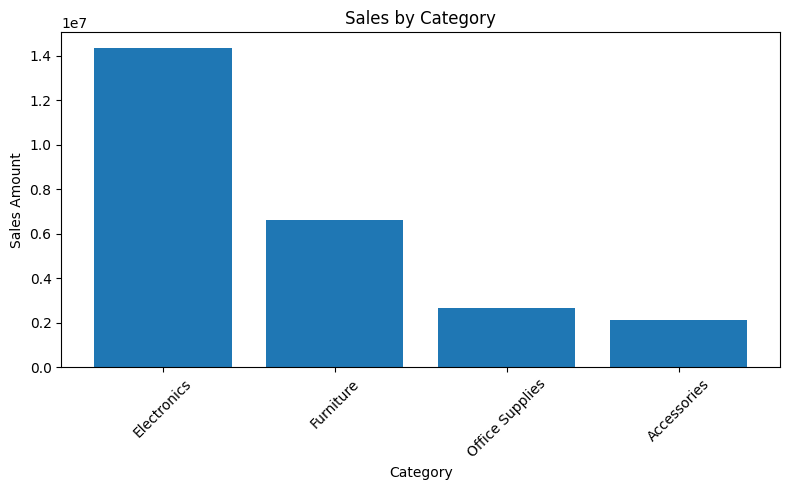

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_sales["Category"],
    category_sales["SalesAmount"]
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Top 10 Products by Sales
نشوف الان وش يطلع معنا

In [27]:
top_products = (
    sales.groupby("ProductName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products

,ProductName,SalesAmount
0,موجه شبكة,1009145.225
1,شاشة عريضة,942983.279
2,مبدل شبكة,867400.480
3,جهاز لوحي للأعمال,835248.352
4,طابعة شبكية,831079.186
5,جهاز لوحي أساسي,814019.760
6,شاشة 24 بوصة,811711.118
7,شاشة 27 بوصة,797516.970
8,طابعة مكتبية,782642.256
9,جهاز لوحي متقدم,737707.824


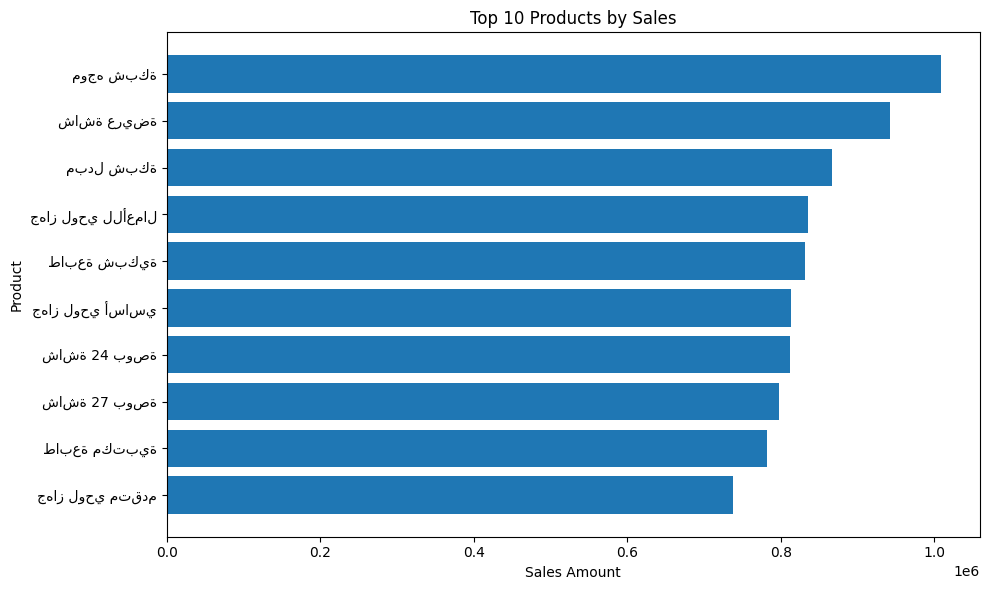

In [28]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_products["ProductName"],
    top_products["SalesAmount"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [29]:
bottom_products = (
    sales.groupby("ProductName")["SalesAmount"]
    .sum()
    .sort_values(ascending=True)
    .head(10)
    .reset_index()
)

bottom_products

,ProductName,SalesAmount
0,دباسة مكتبية,4092.3880
1,قرص SSD خارجي,10353.7525
2,حبر طابعة احترافي,17977.2775
3,حافظة أوراق,19256.7570
4,فأرة لاسلكية,25985.1600
5,ورق طباعة A3,32687.4540
6,ورق ملون,37439.4620
7,ورق ملاحظات,43724.0300
8,لوحة مفاتيح سلكية,43913.3560
9,لوحة مفاتيح ميكانيكية,45940.8070


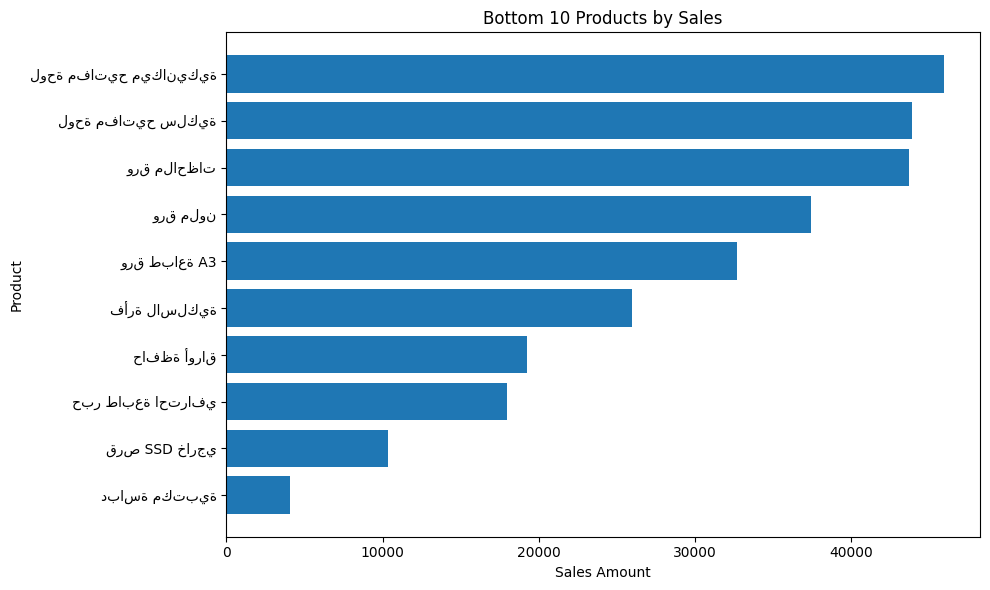

In [30]:
plt.figure(figsize=(10, 6))

plt.barh(
    bottom_products["ProductName"],
    bottom_products["SalesAmount"]
)

plt.title("Bottom 10 Products by Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Product")
plt.tight_layout()

plt.show()

## 5. Customer Analysis

Analyze customer contribution to completed sales and identify the highest-value customers.

In [31]:
sales = sales.merge(
    customers[
        [
            "CustomerID",
            "CustomerName",
            "City",
            "RegionID",
            "CustomerSegment"
        ]
    ],
    on="CustomerID",
    how="left"
)

In [32]:
sales[
    ["CustomerID", "CustomerName", "City", "CustomerSegment", "SalesAmount"]
].head()

,CustomerID,CustomerName,City,CustomerSegment,SalesAmount
0,424,خالد الغامدي,عنيزة,Regular,1317.1260
1,424,خالد الغامدي,عنيزة,Regular,472.3280
2,660,عبدالله العنزي,الظهران,Regular,2221.1095
3,660,عبدالله العنزي,الظهران,Regular,6149.0880
4,575,عبدالعزيز الزهراني,الدمام,Premium,5266.7360


In [33]:
top_customers = (
    sales.groupby(["CustomerID", "CustomerName"])["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers

,CustomerID,CustomerName,SalesAmount
0,210,عبدالعزيز السبيعي,104361.4150
1,415,شهد الرشيدي,95564.7990
2,938,عبير الزهراني,94723.1415
3,827,دانة المالكي,93658.5565
4,354,أمل المالكي,92238.0720
5,557,سارة المطيري,90490.4070
6,6,عبير العنزي,85016.6265
7,401,شهد المطيري,79424.6580
8,772,أمل الشمري,79179.4600
9,265,ريم الغامدي,77609.0200


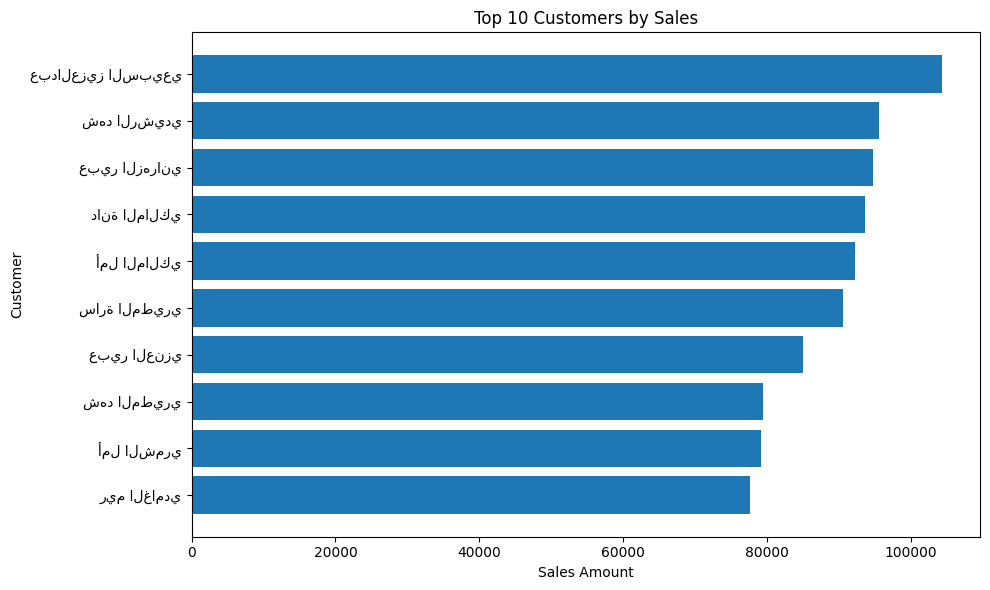

In [34]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["CustomerName"],
    top_customers["SalesAmount"]
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Customer")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [35]:
segment_sales = (
    sales.groupby("CustomerSegment")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

segment_sales

,CustomerSegment,SalesAmount
0,Regular,1.699226e+07
1,Premium,6.325961e+06
2,Corporate,2.428048e+06


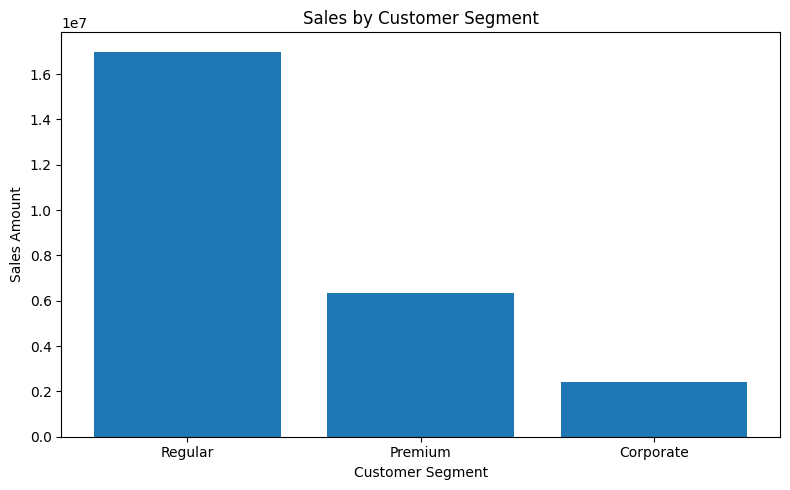

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_sales["CustomerSegment"],
    segment_sales["SalesAmount"]
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales Amount")
plt.tight_layout()

plt.show()

In [37]:
city_sales = (
    sales.groupby("City")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

city_sales

,City,SalesAmount
0,عنيزة,2.924206e+06
1,الرياض,2.580713e+06
2,الطائف,2.464386e+06
3,الظهران,2.451907e+06
4,الدمام,2.301555e+06
5,جدة,2.249666e+06
6,الخرج,2.246369e+06
7,الخبر,2.191948e+06
8,بريدة,2.170257e+06
9,مكة,2.118267e+06


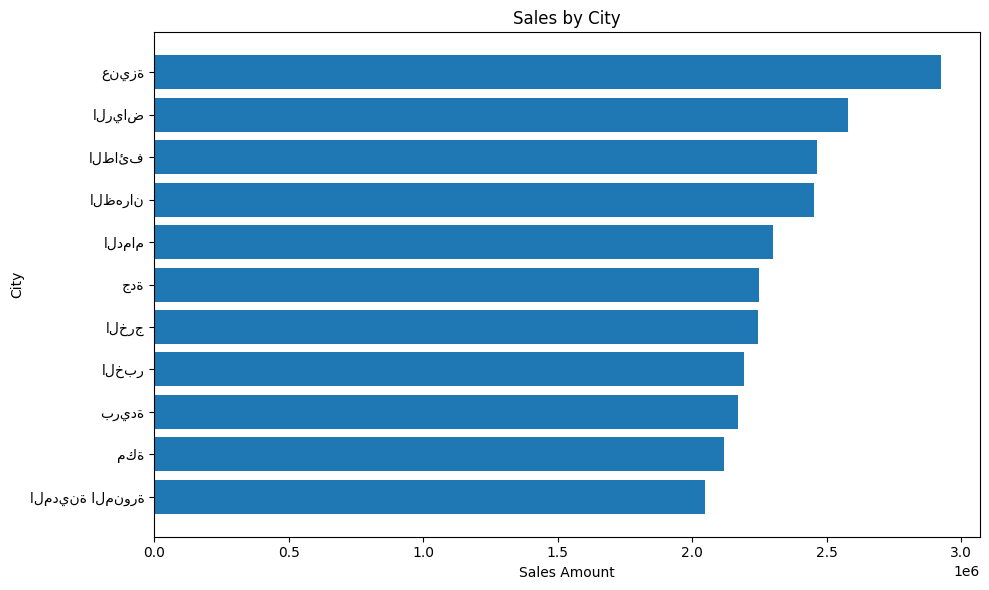

In [38]:
plt.figure(figsize=(10, 6))

plt.barh(
    city_sales["City"],
    city_sales["SalesAmount"]
)

plt.title("Sales by City")
plt.xlabel("Sales Amount")
plt.ylabel("City")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [39]:
sales = sales.merge(
    regions,
    on="RegionID",
    how="left"
)

In [40]:
region_sales = (
    sales.groupby("RegionName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

region_sales

,RegionName,SalesAmount
0,المنطقة الشرقية,7.054698e+06
1,مكة المكرمة,6.861156e+06
2,القصيم,5.128369e+06
3,الرياض,4.597160e+06
4,المدينة المنورة,2.104889e+06


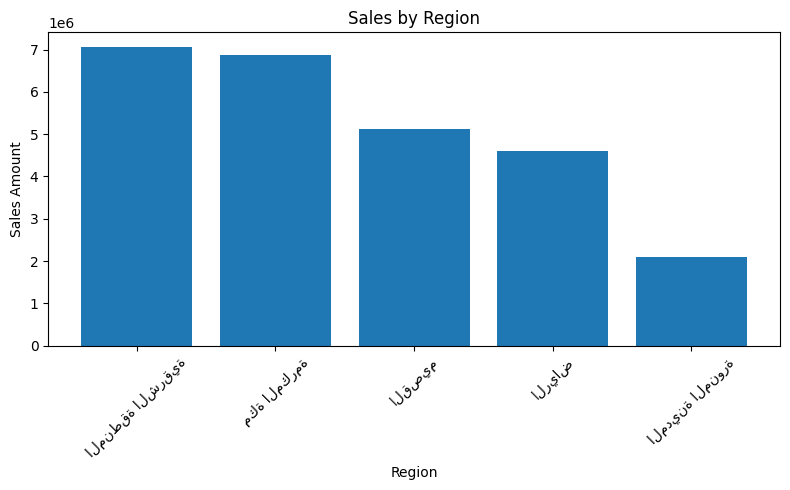

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_sales["RegionName"],
    region_sales["SalesAmount"]
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

في الخطوات اللي قبل غطيت اهم محاور التحليل الاستكشافي الفترة و المنتجات و العملاء و المدن و المناطق

## 6. Order Behavior Analysis

Explore payment methods, shipping methods, and order status patterns.

In [42]:
payment_counts = (
    orders["PaymentMethod"]
    .value_counts()
    .reset_index()
)

payment_counts.columns = ["PaymentMethod", "OrderCount"]

payment_counts

,PaymentMethod,OrderCount
0,Card,1259
1,Digital Wallet,1254
2,Cash,1252
3,Bank Transfer,1235


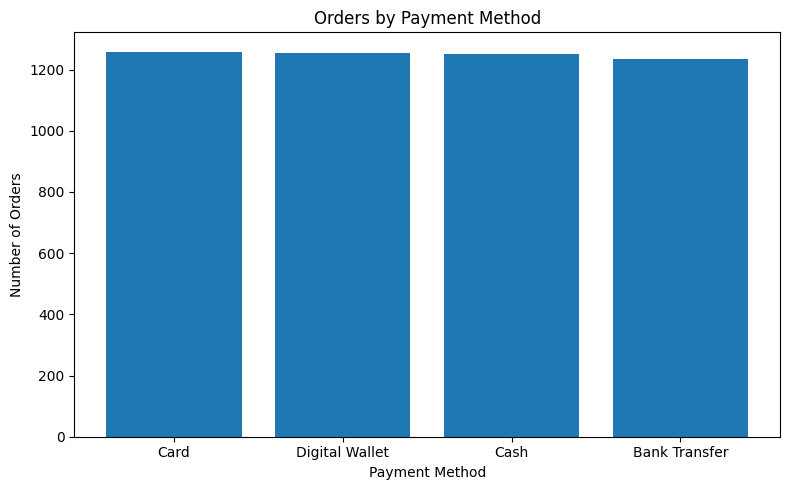

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_counts["PaymentMethod"],
    payment_counts["OrderCount"]
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.show()

In [44]:
shipping_counts = (
    orders["ShippingMethod"]
    .value_counts()
    .reset_index()
)

shipping_counts.columns = ["ShippingMethod", "OrderCount"]

shipping_counts

,ShippingMethod,OrderCount
0,Delivery,3503
1,Pickup,975
2,Express,522


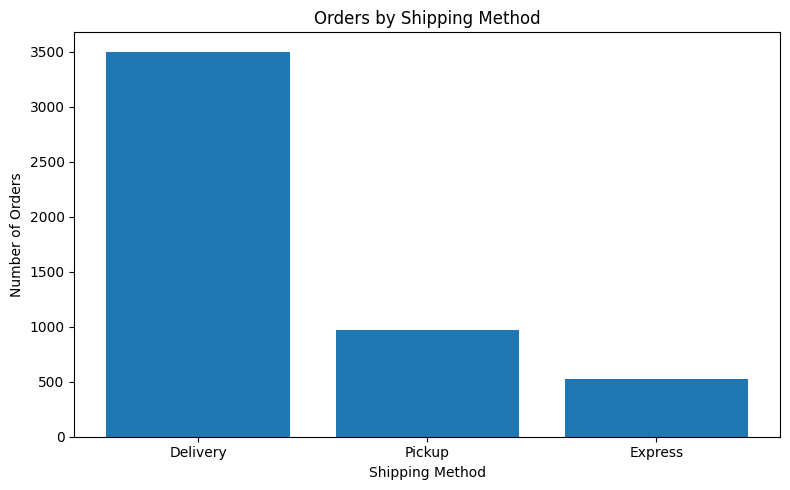

In [45]:
plt.figure(figsize=(8, 5))

plt.bar(
    shipping_counts["ShippingMethod"],
    shipping_counts["OrderCount"]
)

plt.title("Orders by Shipping Method")
plt.xlabel("Shipping Method")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.show()

In [46]:
status_counts = (
    orders["OrderStatus"]
    .value_counts()
    .reset_index()
)

status_counts.columns = ["OrderStatus", "OrderCount"]

status_counts

,OrderStatus,OrderCount
0,Completed,4038
1,Cancelled,363
2,Returned,323
3,Pending,276


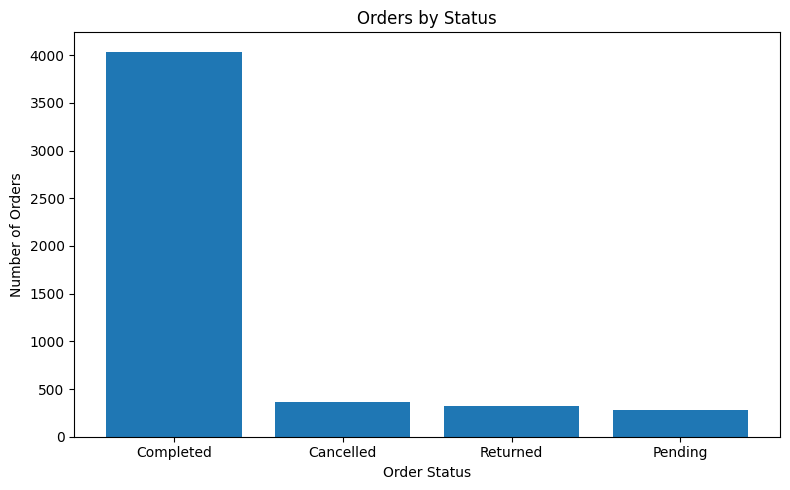

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(
    status_counts["OrderStatus"],
    status_counts["OrderCount"]
)

plt.title("Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.show()